In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [7]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

In [8]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

N_SPLITS = 5
N_VOTING_WINDOWS = 7
MINIMUM_PACKET_COUNT = 1
MAX_TRAIN_WINDOWS_PER_DEVICE = 40_000
RANDOM_STATE = 42
WINDOW_SECONDS = 4
MIN_VOTING_WINDOWS = 7
MAX_VOTING_WINDOWS = 51

In [9]:
def calculate_features(
    file_paths: Iterable[str],
    window: float,
    device_mapping_list: Dict[str, Dict[str,str]]
) -> Tuple[pd.DataFrame, float]:
    if window <= 0:
        raise ValueError("window must be greater than 0.")

    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
        "eth.dst"
    ]

    all_features = []
    start_time = time.perf_counter()

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category"
            },
        )

        valid_macs = set(device_mapping_list.keys())

        raw_df = raw_df[
            raw_df["eth.src"].isin(valid_macs)
            & raw_df["eth.dst"].isin(valid_macs)
        ]

        df = raw_df[["frame.time_epoch","frame.len","eth.src"]].copy()

        if df.empty:
            print(f"{file_path} contains empty set")
            continue

        capture_start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        basic_features = (
            df.groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),

                # Timestamp of the first packet from this device
                # within this window.
                timestamp=("frame.time_epoch", "min"),
            )
            .reset_index()
        )

        # Retain which input capture produced each feature row.
        basic_features["capture_id"] = Path(file_path).stem

        all_features.append(basic_features)

    elapsed_time = time.perf_counter() - start_time

    if not all_features:
        empty_result = pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "timestamp",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )
        return empty_result, elapsed_time

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int32")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    result = result.sort_values(
        ["timestamp", "eth.src"],
        ignore_index=True,
    )

    return result, elapsed_time

In [10]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [11]:
features, _ = calculate_features(file_paths=csv_files_1, window=WINDOW_SECONDS, device_mapping_list=device_dict_1)

In [12]:
features.head(5)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id
0,0,18:b7:9e:02:20:44,3,202,1.474553e+09,16-09-23
1,0,14:cc:20:51:33:ea,17,1363,1.474553e+09,16-09-23
2,0,d0:52:a8:00:67:5e,3,259,1.474553e+09,16-09-23
3,0,70:ee:50:18:34:43,3,284,1.474553e+09,16-09-23
4,0,ec:1a:59:79:f4:89,1,42,1.474553e+09,16-09-23


In [13]:
labeled_feature = label_features(features, device_dict_1)

# Re-EDA

In [14]:
eda_df = labeled_feature.copy()

In [15]:
result = (
    eda_df.groupby("eth.src", observed=True)["capture_id"]
      .unique()
      .reset_index()
)
result

,eth.src,capture_id
0,00:16:6c:ab:6b:88,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
1,00:24:e4:11:18:a8,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07]"
2,00:24:e4:1b:6f:96,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
3,00:24:e4:20:28:c6,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
4,00:62:6e:51:27:2e,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
5,08:21:ef:3b:fc:e3,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
6,14:cc:20:51:33:ea,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
7,18:b4:30:25:be:e4,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11]"
8,18:b7:9e:02:20:44,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
9,30:8c:fb:2f:e4:b2,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"


In [16]:
df = eda_df

In [17]:
min_windows = N_VOTING_WINDOWS + 1

# Count windows for each (eth.src, capture_id)
capture_counts = (
    df.groupby(["eth.src", "capture_id"])
      .size()
      .reset_index(name="window_count")
)

# For each device, check whether ANY capture_id has enough windows
device_validity = (
    capture_counts
    .groupby("eth.src")["window_count"]
    .max()
)

# Devices where NONE of the capture_ids have enough windows
devices_to_drop = device_validity[
    device_validity < min_windows
].index

# Print information about dropped devices
dropped_device_info = (
    df[df["eth.src"].isin(devices_to_drop)]
    [["eth.src", "is_iot_device", "device_type", "vendor"]]
    .drop_duplicates()
    .sort_values("eth.src")
)

print("Dropped devices:")
print(dropped_device_info.to_string(index=False))

# Show capture/window counts for those dropped devices
print("\nCapture details:")
print(
    capture_counts[
        capture_counts["eth.src"].isin(devices_to_drop)
    ].to_string(index=False)
)

# Drop the devices completely
df_filtered = df[
    ~df["eth.src"].isin(devices_to_drop)
].copy()

remaining_device_info = (
    df_filtered[
        ["eth.src", "is_iot_device", "device_type", "vendor"]
    ]
    .drop_duplicates()
    .sort_values("eth.src")
)

print("\nRemaining devices:")
print(remaining_device_info.to_string(index=False))

print(f"\nNumber of remaining devices: {remaining_device_info['eth.src'].nunique()}")

# Optional summary counts
print("\nRemaining devices by IoT label:")
print(
    remaining_device_info["is_iot_device"]
    .value_counts(dropna=False)
)

print("\nRemaining devices by device type:")
print(
    remaining_device_info["device_type"]
    .value_counts(dropna=False)
)


Dropped devices:
          eth.src  is_iot_device            device_type   vendor
74:6a:89:00:2e:25              1 blood pressure monitor Blipcare

Capture details:
          eth.src capture_id  window_count
74:6a:89:00:2e:25   16-09-23             3
74:6a:89:00:2e:25   16-09-28             6
74:6a:89:00:2e:25   16-10-04             3

Remaining devices:
          eth.src  is_iot_device     device_type              vendor
00:16:6c:ab:6b:88              1          camera             Samsung
00:24:e4:11:18:a8              1    baby monitor            Withings
00:24:e4:1b:6f:96              1     smart scale            Withings
00:24:e4:20:28:c6              1    sleep sensor            Withings
00:62:6e:51:27:2e              1          camera             Insteon
08:21:ef:3b:fc:e3              0             NaN                 NaN
14:cc:20:51:33:ea              0             NaN                 NaN
18:b4:30:25:be:e4              1     smoke alarm                Nest
18:b7:9e:02:20:44     

# Try different threshold on the average probability with different window

In [18]:
def select_voting_window_indices(
    df: pd.DataFrame,
    voting_window: int,
    random_state: int | None = None,
) -> list[int]:

    rng = np.random.default_rng(random_state)

    min_windows = voting_window + 1
    selected_indices = []

    for eth_src, device_df in df.groupby("eth.src", observed=True):

        capture_counts = (
            device_df.groupby("capture_id", observed=True)
            .size()
        )

        eligible_capture_ids = capture_counts[
            capture_counts >= min_windows
        ].index.to_numpy()

        if len(eligible_capture_ids) == 0:
            continue

        # Randomly choose one eligible capture
        selected_capture_id = rng.choice(eligible_capture_ids)

        # Sort windows while preserving original dataframe indices
        capture_df = (
            device_df[
                device_df["capture_id"] == selected_capture_id
            ]
            .sort_values("window")
        )

        num_windows = len(capture_df)

        max_start = num_windows - voting_window

        start_idx = rng.integers(
            low=0,
            high=max_start + 1,
        )

        end_idx = start_idx + voting_window

        # Get original dataframe indices
        indices = capture_df.iloc[start_idx:end_idx].index.tolist()

        selected_indices.extend(indices)

    return selected_indices

In [19]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight=None,
        random_state=random_seed,
    )

In [24]:
thresholds = np.arange(0.3, 1.0, 0.05)
thresholds

array([0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 ,
       0.85, 0.9 , 0.95])

In [25]:
def filter_devices_by_voting_windows(
    feature: pd.DataFrame,
    voting_window: int,
) -> pd.DataFrame:
    min_windows = voting_window + 1
    df = feature.copy()
    # Count windows for each (eth.src, capture_id)
    capture_counts = (
        df.groupby(["eth.src", "capture_id"])
        .size()
        .reset_index(name="window_count")
    )

    # For each device, check whether ANY capture_id has enough windows
    device_validity = (
        capture_counts
        .groupby("eth.src")["window_count"]
        .max()
    )

    # Devices where NONE of the capture_ids have enough windows
    devices_to_drop = device_validity[
        device_validity < min_windows
    ].index

    # Print information about dropped devices
    dropped_device_info = (
        df[df["eth.src"].isin(devices_to_drop)]
        [["eth.src", "is_iot_device", "device_type", "vendor"]]
        .drop_duplicates()
        .sort_values("eth.src")
    )

    # Drop the devices completely
    df_filtered = df[
        ~df["eth.src"].isin(devices_to_drop)
    ].copy()

    return df_filtered

In [26]:
def average_probablity_vote_with_custom_threshold(probabilities: list[float], threshold: float) -> int:
    if len(probabilities) == 0:
        raise ValueError("The probabilities list is empty.")

    avg_probability = np.mean(probabilities)

    return int(avg_probability >= threshold)

In [27]:
def train_and_evaluate_with_different_threshold(train_df: pd.DataFrame, val_df: pd.DataFrame, majority_vote_rule, threshold_list: List[float]) -> Dict[float, float]:
    X_train = train_df[FEATURE_COLUMNS]
    y_train = train_df[LABEL_COLUMN]

    X_val = val_df[FEATURE_COLUMNS]
    y_val = val_df[LABEL_COLUMN]

    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)

    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    # Probability for each class
    each_window_proba = model.predict_proba(X_val_scaled)

    # Get probability of class 1
    class_1_index = np.where(model.classes_ == 1)[0][0]
    each_window_iot_proba = each_window_proba[:, class_1_index]

    # Avoid modifying the original validation dataframe
    val_df = val_df.copy()

    val_df["iot_probability"] = each_window_iot_proba

    # Group window probabilities by device
    prediction_by_device = (
        val_df.groupby("eth.src")["iot_probability"]
        .apply(list)
        .reset_index()
    )

    predict_and_true_by_device = label_features(
        prediction_by_device,
        device_dict_1
    )
    accuracies = {}
    for threshold in threshold_list:
        # Aggregate probabilities across voting windows
        predict_and_true_by_device[f"aggregated_prediction_{threshold}"] = (
            predict_and_true_by_device["iot_probability"]
            .apply(lambda x: majority_vote_rule(x, threshold))
        )

        accuracy = accuracy_score(
            predict_and_true_by_device["is_iot_device"],
            predict_and_true_by_device[f"aggregated_prediction_{threshold}"]
        )
        misclassified_eth_src = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"]
            != predict_and_true_by_device[f"aggregated_prediction_{threshold}"],
            "eth.src"
        ].tolist()

        total_device_count = predict_and_true_by_device["eth.src"].nunique()
        iot_device_count = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"] == 1,
            "eth.src"
        ].nunique()
        non_iot_device_count = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"] == 0,
            "eth.src"
        ].nunique()
        
        metadata = {
            "accuracy": accuracy, 
            "missclassified": misclassified_eth_src, 
            "total_device_count": total_device_count, 
            "iot_device_count": iot_device_count,
            "non_iot_device_count": non_iot_device_count
        }
        accuracies[threshold] = metadata

    return accuracies

In [29]:
labeled_features_copy = labeled_feature.copy()
all_devices = set(labeled_features_copy["eth.src"].unique())
metric = []
for voting_window in range(MIN_VOTING_WINDOWS, MAX_VOTING_WINDOWS + 1):
    metric_cur_window = []

    filtered_df = filter_devices_by_voting_windows(labeled_features_copy, voting_window)
    val_indices = select_voting_window_indices(
        filtered_df,
        voting_window,
        random_state=RANDOM_STATE + voting_window, # Increase the chance of not selecting the same window 
    )

    filtered_device_set = set(filtered_df["eth.src"].unique())
    dropped_device = all_devices - filtered_device_set
    dropped_iot_device, dropped_non_iot_device = [], []
    for mac in dropped_device:
        if mac in device_dict_1:
            if device_dict_1[mac]["is_iot_device"] == 1:
                dropped_iot_device.append((mac, device_dict_1[mac]["device_name"]))
            else:
                dropped_non_iot_device.append((mac, device_dict_1[mac]["device_name"]))
        else:
            raise ValueError(f"MAC address {mac} does not exist")


    train_indices = filtered_df.index.difference(val_indices)
    train_df, val_df = filtered_df.loc[train_indices], filtered_df.loc[val_indices]
    accuracies = train_and_evaluate_with_different_threshold(train_df, val_df, average_probablity_vote_with_custom_threshold, thresholds)
    for threshold in accuracies:
        metadata = accuracies[threshold]
        metadata["dropped_iot_devices"] = dropped_iot_device
        metadata["dropped_non_iot_device"] = dropped_non_iot_device
        metadata["voting_window"] = voting_window
        metadata["threshold"] = threshold
        metric_cur_window.append(metadata)
    metric.extend(metric_cur_window)

In [30]:
metric_df = pd.DataFrame(metric)

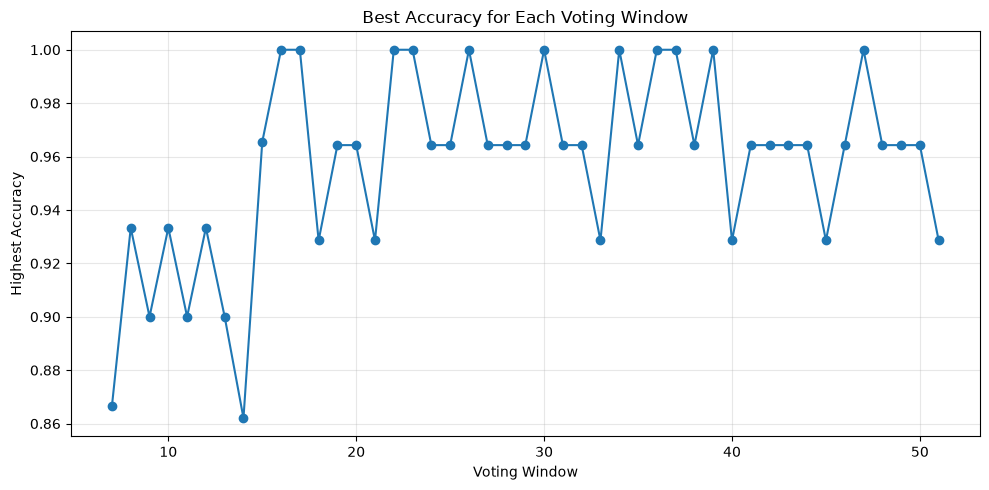

In [31]:
best_per_window = (
    metric_df.loc[
        metric_df.groupby("voting_window")["accuracy"].idxmax()
    ]
    .sort_values("voting_window")
)

plt.figure(figsize=(10, 5))

plt.plot(
    best_per_window["voting_window"],
    best_per_window["accuracy"],
    marker="o"
)

plt.xlabel("Voting Window")
plt.ylabel("Highest Accuracy")
plt.title("Best Accuracy for Each Voting Window")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
metric_df.sort_values("accuracy", ascending=False).head(35)

,accuracy,missclassified,total_device_count,iot_device_count,non_iot_device_count,dropped_iot_devices,dropped_non_iot_device,voting_window,threshold
384,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],34,0.60
273,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],26,0.65
214,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],22,0.50
412,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],36,0.60
425,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],37,0.55
426,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],37,0.60
271,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],26,0.55
272,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],26,0.60
144,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],17,0.50
131,1.000000,[],28,20,8,"[(18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale), (74:6a:89:00:2e:25, Blipcare Blood Pressure meter)]",[],16,0.55
